# P4: RL & MCTS

[Instructions are the same as they have been. You know the drill by now.]

To begin, you will revisit the graph problem from the last assignment, yet this time you will solve it using Q-Learning!

In [1]:
# Starter Code: Graph definition and plotting (the same as P3)

import matplotlib.pyplot as plt
import numpy as np
import random


def get_random_adjacency(band_size, num_nodes, edge_rate=1.0, seed=695):
    random.seed(seed)
    mat = np.zeros((num_nodes, num_nodes))
    for ii in range(num_nodes):
        mat[ii, ii] = 1.0
        for jj in range(ii + 1, min(ii + band_size, num_nodes)):
            val = 1.0 * (random.random() < edge_rate)
            mat[ii, jj] = val
            mat[jj, ii] = val
    return mat


def plot_adjacency_mat(mat):
    plt.figure(dpi=150)
    plt.xticks([], [])
    plt.yticks([], [])
    plt.imshow(mat, interpolation="none")


class AdjacencyWorld(object):
    def __init__(
        self, num_nodes, band_size=10, edge_rate=0.5, random_move_chance=0.5, seed=695
    ):
        self.mat = get_random_adjacency(
            band_size=band_size, num_nodes=num_nodes, edge_rate=edge_rate, seed=seed
        )
        self.states = list(range(num_nodes))
        self.rewards = -1 * np.ones((num_nodes))
        self.goal = num_nodes // 2
        self.rewards[self.goal] = 10
        self.random_move_chance = random_move_chance

    def get_actions_for_state(self, state):
        """Get the available 'moves' from the current state.
        return: list of indices connected to 'state'."""
        return np.where(self.mat[state])[0].tolist()

    def get_transition_probs(self, state, action):
        """Get a list of the transition probabilities for a state and action."""
        actions = self.get_actions_for_state(state)
        num_actions = len(actions)
        prob_vec = np.zeros_like(self.rewards)
        for rand_action in actions:
            prob_vec[rand_action] = self.random_move_chance / num_actions

        prob_vec[action] += 1 - self.random_move_chance
        return prob_vec

    def get_random_state(self):
        return random.choice(self.states)

    def execute_action(self, state, action):
        assert action in self.get_actions_for_state(state)
        probs = self.get_transition_probs(state, action)
        new_state = np.random.choice(self.states, p=probs)
        return self.rewards[new_state], new_state

## P4.1 Q Learning

Next, you'll be implementing Q Learning. Instructions here are a bit sparse, but I figure you probably know what you're doing by now!

**TASK** Implement Q Learning (use the lecture slides as a reference).

**TASK** Complete the `evaluate_policy` function using your implementation from the previous assignment (or mine). We will not grade this function, but it is necessary to complete your Q Learning evaluation code.

**CODE** Include your Q Learning implementation in your writeup

**PLOTS** Run the evaluation code below. Include all plots and the results (the average value for each value of the learning rate) in your writeup. You should notice the performance is best for the 0.005–0.02 range.

**QUESTION** (1-3 sentences) The rate of convergence for Q learning is significantly slower than that of Value Iteration. What information does Value Iteration have access to (and indeed makes use of) that makes it converge faster?

**QUESTION** (3-5 sentences) When the learning rate is very low, the performance is not particularly good. From looking at the plots of the total reward over time, what is likely the cause? How would you fix this issue (without changing the learning rate)?

**QUESTION** (2-4 sentences) When the learning rate is too high, the performance is also not very good. Why does this happen?

In [2]:
# Starter Code: Q Learning


def evaluate_policy(env, policy, gamma=0.98):
    """Returns a list of values[state]. (Your implementation from P3.)"""
    # raise NotImplementedError()
    P = np.array([env.get_transition_probs(s, policy[s]) for s in env.states])
    return np.linalg.solve(np.eye(len(env.states)) - gamma * P, env.rewards)


def Q_learning(
    env,
    num_iterations,
    num_steps=30,
    gamma=0.98,
    learning_rate=0.005,
    epsilon=0.1,
    seed=695,
):
    random.seed(seed)
    np.random.seed(seed)
    Q_s_a = np.zeros((len(env.states), len(env.states)))
    total_rewards = []
    # Iterate
    for ii in range(num_iterations):
        # Rollout
        total_reward = 0
        state = env.get_random_state()
        for ii in range(num_steps):
            # Take an action and get the reward
            # raise NotImplementedError()
            actions = env.get_actions_for_state(state)
            if random.random() < epsilon:
                action = random.choice(actions)
            else:
                action = actions[np.argmax(Q_s_a[state, actions])]

            r, new_state = env.execute_action(state, action)

            # Update Q
            # raise NotImplementedError()
            next_actions = env.get_actions_for_state(new_state)
            best_next = np.max(Q_s_a[new_state, next_actions])
            Q_s_a[state, action] += learning_rate * (r + gamma * best_next - Q_s_a[state, action])

            # Update reward and state
            total_reward += r
            state = new_state

        total_rewards.append(total_reward)

    policy = np.zeros(len(env.states))
    for state in env.states:
        actions = env.get_actions_for_state(state)
        action_ind = np.argmax(Q_s_a[state, actions])
        policy[state] = actions[action_ind]
    return list(policy.astype(int)), total_rewards

Q Learning Avg. Value (0.001): 225.94759807764336
Q Learning Avg. Value (0.005): 262.90353903169637
Q Learning Avg. Value (0.02): 260.698069192514
Q Learning Avg. Value (0.1): 229.03788753554144
Q Learning Avg. Value (1.0): -39.913918072214074


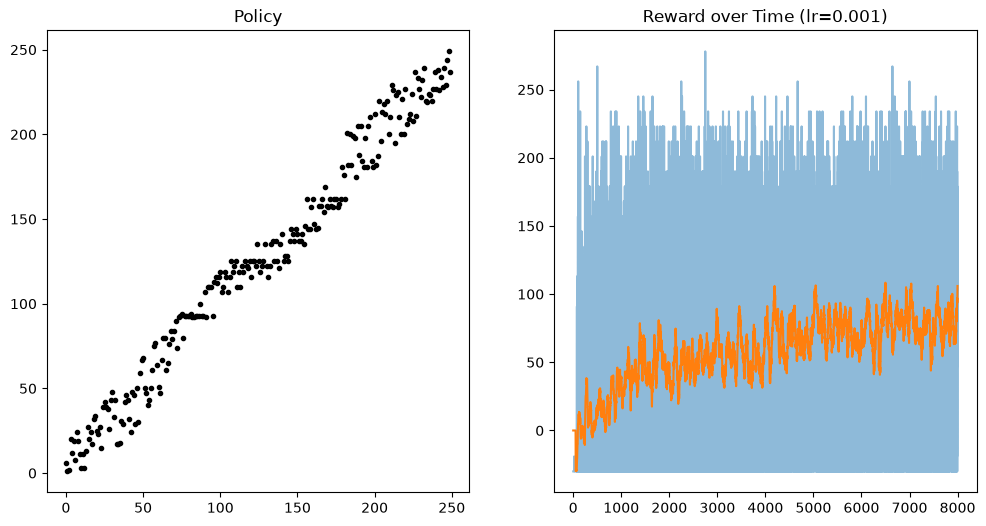

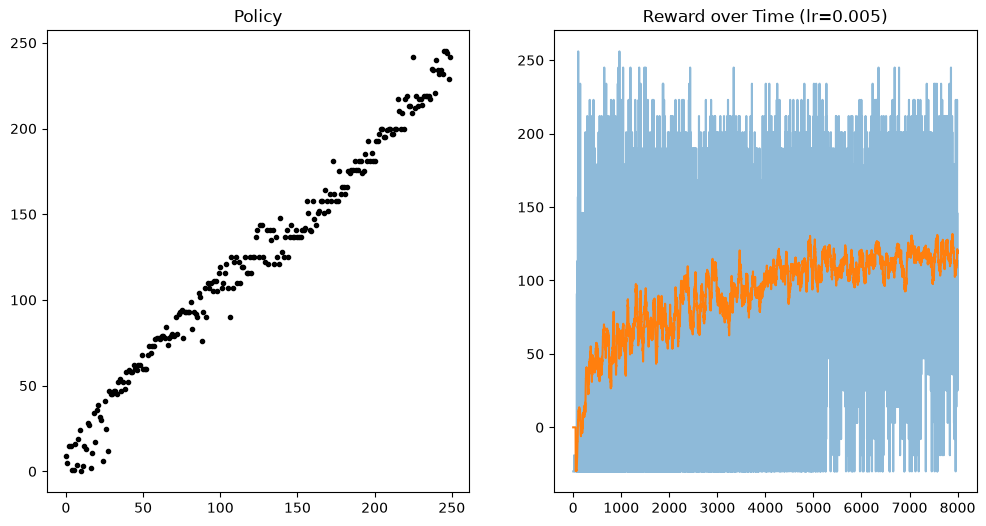

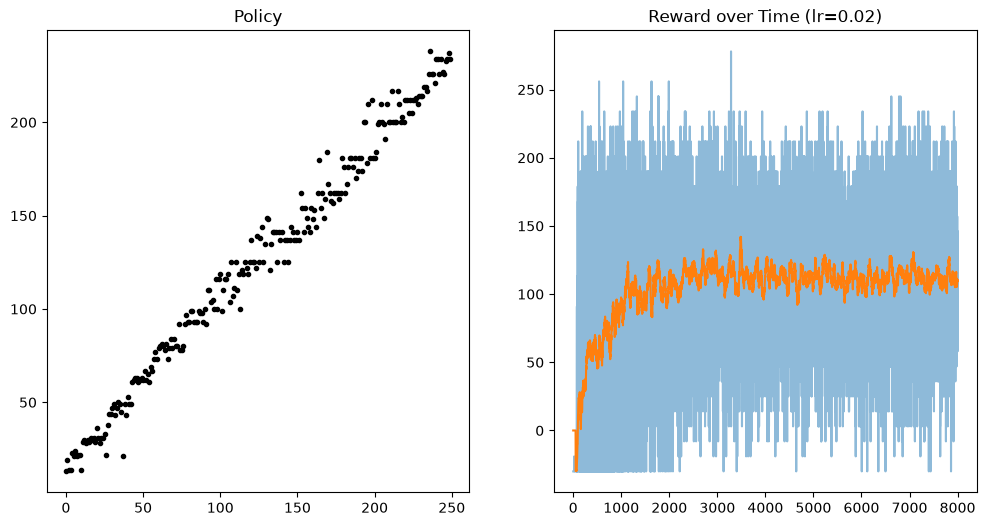

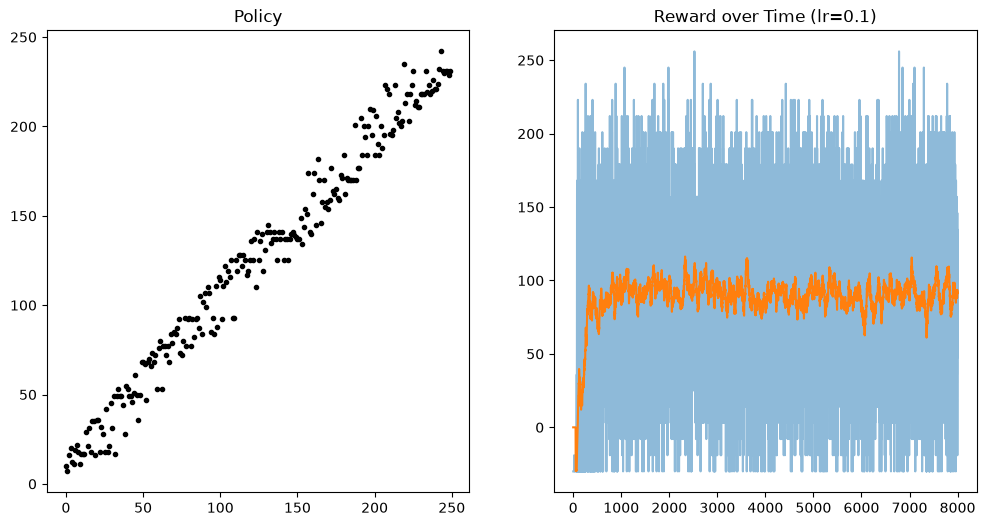

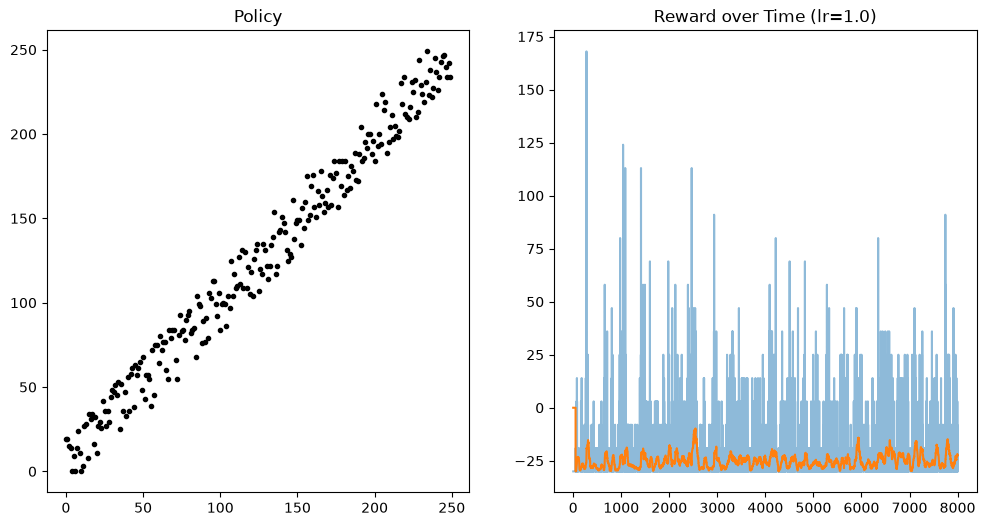

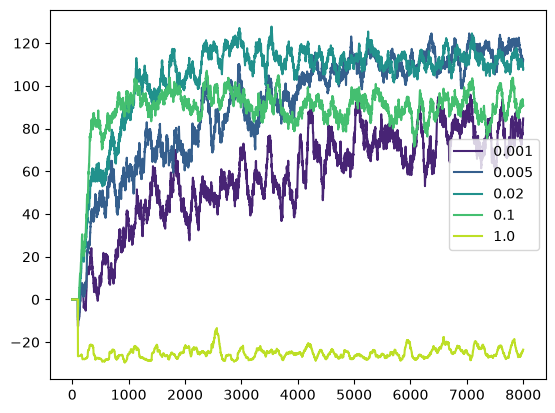

In [3]:
# Evaluation code

world = AdjacencyWorld(250, band_size=20, edge_rate=0.4, random_move_chance=0.3)


def smooth_data(data, window_width=50):
    summed_data = np.cumsum(data)
    sm_data = (summed_data[window_width:] - summed_data[:-window_width]) / window_width
    return np.concatenate([np.zeros(window_width), sm_data])


def evaluate_q_learning(learning_rate):
    policy_ql, rewards = Q_learning(
        world, num_iterations=8000, learning_rate=learning_rate
    )
    pv = evaluate_policy(world, policy_ql)
    print(f"Q Learning Avg. Value ({learning_rate}): {np.mean(pv)}")

    plt.figure(figsize=(12, 6))
    plt.subplot(121)
    plt.plot(policy_ql, "k.")
    plt.title("Policy")

    plt.subplot(122)
    plt.plot(rewards, alpha=0.5)
    plt.plot(smooth_data(rewards))
    plt.title(f"Reward over Time (lr={learning_rate})")

    return rewards


# policy_pi, _ = policy_iteration(world, num_iterations=100, gamma=0.98)
# pv = evaluate_policy(world, policy_pi)
# print(f"Policy Iteration Avg. Value: {np.mean(pv)}")

rewards_0p001 = evaluate_q_learning(learning_rate=0.001)
rewards_0p005 = evaluate_q_learning(learning_rate=0.005)
rewards_0p02 = evaluate_q_learning(learning_rate=0.02)
rewards_0p1 = evaluate_q_learning(learning_rate=0.10)
rewards_1 = evaluate_q_learning(learning_rate=1.00)

from matplotlib import colormaps

plt.figure()
cmap = colormaps["viridis"]
plt.plot(smooth_data(rewards_0p001, 100), color=cmap(0.1))
plt.plot(smooth_data(rewards_0p005, 100), color=cmap(0.3))
plt.plot(smooth_data(rewards_0p02, 100), color=cmap(0.5))
plt.plot(smooth_data(rewards_0p1, 100), color=cmap(0.7))
plt.plot(smooth_data(rewards_1, 100), color=cmap(0.9))
plt.legend(["0.001", "0.005", "0.02", "0.1", "1.0"])
None

## P4.2 Deep Q Learning (following a tutorial)

In P4.1, you implemented tabular Q learning, which stores a separate value for every state-action pair. *Deep Reinforcement Learning* instead uses deep learning to approximate the Q function, which we will discuss in more detail in the coming lectures. While deep learning is somewhat out of scope for this class, I thought it would be instructive for you to follow a tutorial for Deep RL and tune the parameters a bit. The following link takes you to a Google Colab notebook, which lets you connect to a (free, with a Google account) cloud GPU on which the experiments will be run:

- Link to the tutorial page: https://pytorch.org/tutorials/intermediate/reinforcement_q_learning.html
- In that page is a link to the Google Colab page: https://colab.research.google.com/github/pytorch/tutorials/blob/gh-pages/_downloads/9da0471a9eeb2351a488cd4b44fc6bbf/reinforcement_q_learning.ipynb#scrollTo=sSQst1iEFdGV

**TASK** Before we begin, navigate to the "Training Loop" section and modify the `num_episodes` variable (set to 50 when the GPU is not used in the second code block in that section) so `num_episodes = 600` even when you're using the CPU. This is important because, as the text above this block states: "50 episodes is insufficient for to observe good performance on CartPole."

**TASK/PLOT** After making the modification, click on `Runtime` in the top menu bar and `Restart and run all`. This will run all the code and train a Deep Q Network to solve the Cartpole V1 environment. Note: if this box is grayed out, you may need to click "Connect" on the top right to connect to the CPU/GPU. Include the resulting performance plot in your writeup, which should show return + average return vs episode.

**QUESTION** How does the algorithm perform? How does the final average return compare to the maximum possible value?

**TASK/PLOTS** Now you'll modify some parameters! The system is pretty dialed in as is, but it's somewhat slow to converge. Navigate to the Hyperparameters section under Training and modify a few things: you should **run three different configurations of hyperparameters**. Include: (i) the hyperparameters you changed, (ii) why you thought to change those (e.g., what was your process for deciding), and (iii) the results plot. Note that you are not required to improve performance, so you will not be evaluated on final performance.

**QUESTION** (3--6 sentences) Describe how parameter tuning went? Include any surprises you encountered along the way.

## P4.3 Connect Four and MCTS

I have provided you with a (pure python) implementation of the popular turn-based game "Connect Four". In this game, you 'drop' pieces of different color into the game board, trying to get four in a row (along any axis) before your opponent can. In this question, I have provided you with an implementation of minimax search, which you will use to compare against your own implementation of Monte Carlo Tree Search.

### P4.3.1 Minimax

I have provided you with an already-complete minimax algorithm implementation. The algorithm has an element of randomness in it: if multiple actions are of equal value, it picks one at random. The evaluation code below pits two different minimax algorithms against one another: one that runs at depth 5 and one that runs at depth 3.

**QUESTION** (2-3 sentences) What is the evaluation function being used to evaluate the goodness of a board state once the maximum depth is reached? How "useful" is the value function I have provided?

**TASK** Run the evaluation code below and observe the results.

**RESULTS** Include the win/draw counts in your writeup.

**QUESTION** (1-3 sentences) You may notice that sometimes the depth-3 minimax search wins against the depth-5 minimax search. How is this possible?

In [4]:
# Connect Four Implementation
import copy
import numpy as np
import random


class ConnectFourBoard(object):
    def __init__(self, nrows=6, ncols=7):
        self.current_player = 1
        self.nrows = nrows
        self.ncols = ncols
        self.board = np.zeros((nrows, ncols), int)
        self.winner = None

    def get_moves(self):
        return np.where(self.board[0] == 0)[0]

    def _check_winner(self, row, col):
        """Check if the move in col ended the game.
        Not wonderful code, but easy to follow and debug."""
        b, r, c = self.board, row, col

        # Diagonal 1
        if r - 3 >= 0 and c - 3 >= 0:
            if b[r, c] == b[r - 1, c - 1] == b[r - 2, c - 2] == b[r - 3, c - 3]:
                self.winner = b[r, c]
                return
        if r - 2 >= 0 and c - 2 >= 0 and r + 1 < self.nrows and c + 1 < self.ncols:
            if b[r + 1, c + 1] == b[r, c] == b[r - 1, c - 1] == b[r - 2, c - 2]:
                self.winner = b[r, c]
                return
        if r - 1 >= 0 and c - 1 >= 0 and r + 2 < self.nrows and c + 2 < self.ncols:
            if b[r + 2, c + 2] == b[r + 1, c + 1] == b[r, c] == b[r - 1, c - 1]:
                self.winner = b[r, c]
                return
        if r + 3 < self.nrows and c + 3 < self.ncols:
            if b[r + 3, c + 3] == b[r + 2, c + 2] == b[r + 1, c + 1] == b[r, c]:
                self.winner = b[r, c]
                return

        # Diagonal 2
        if r - 3 >= 0 and c + 3 < self.ncols:
            if b[r, c] == b[r - 1, c + 1] == b[r - 2, c + 2] == b[r - 3, c + 3]:
                self.winner = b[r, c]
                return
        if r - 2 >= 0 and c + 2 < self.ncols and r + 1 < self.nrows and c - 1 >= 0:
            if b[r + 1, c - 1] == b[r, c] == b[r - 1, c + 1] == b[r - 2, c + 2]:
                self.winner = b[r, c]
                return
        if r - 1 >= 0 and c + 1 < self.ncols and r + 2 < self.nrows and c - 2 >= 0:
            if b[r + 2, c - 2] == b[r + 1, c - 1] == b[r, c] == b[r - 1, c + 1]:
                self.winner = b[r, c]
                return
        if r + 3 < self.nrows and c - 3 >= 0:
            if b[r + 3, c - 3] == b[r + 2, c - 2] == b[r + 1, c - 1] == b[r, c]:
                self.winner = b[r, c]
                return

        # Flat
        if c + 3 < self.ncols:
            if b[r, c] == b[r, c + 1] == b[r, c + 2] == b[r, c + 3]:
                self.winner = b[r, c]
                return
        if c + 2 < self.ncols and c - 1 >= 0:
            if b[r, c - 1] == b[r, c] == b[r, c + 1] == b[r, c + 2]:
                self.winner = b[r, c]
                return
        if c + 1 < self.ncols and c - 2 >= 0:
            if b[r, c - 2] == b[r, c - 1] == b[r, c] == b[r, c + 1]:
                self.winner = b[r, c]
                return
        if c - 3 >= 0:
            if b[r, c - 3] == b[r, c - 2] == b[r, c - 1] == b[r, c]:
                self.winner = b[r, c]
                return

        # Down
        if r - 3 >= 0:
            if b[r, c] == b[r - 1, c] == b[r - 2, c] == b[r - 3, c]:
                self.winner = b[r, c]
                return
        if r + 3 < self.nrows:
            if b[r + 3, c] == b[r + 2, c] == b[r + 1, c] == b[r, c]:
                self.winner = b[r, c]
                return

    def copy(self):
        return copy.deepcopy(self)

    def play_move(self, col):
        try:
            row = np.where(self.board[:, col] == 0)[0][-1]
        except IndexError:
            raise ValueError(f"Cannot play column '{col}'.")
        self.board[row, col] = self.current_player

        # Check for a winner
        self._check_winner(row, col)

        # Check if no more moves
        if len(self.get_moves()) == 0:
            self.winner = 0

        # Switch player
        if self.current_player == 1:
            self.current_player = 2
        else:
            self.current_player = 1

        return self

    def play_random_move(self):
        self.play_move(random.choice(self.get_moves()))

    def play_random_moves_until_done(self):
        while self.winner is None:
            self.play_random_move()

        return self.winner

    def __str__(self):
        string = ""
        for row in self.board:
            string += f"|{row}|\n"
        string += "=" * (2 * self.ncols + 3)

        return string


# Some simple tests
print("A board and randomly playing moves.")
board = ConnectFourBoard(nrows=6, ncols=7)
print(board)
print(board.get_moves())

while board.winner is None:
    board.play_random_move()

print(board)
print(board.winner)

A board and randomly playing moves.
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
[0 1 2 3 4 5 6]
|[0 0 0 0 0 2 0]|
|[0 1 0 0 0 2 0]|
|[1 2 0 1 0 2 0]|
|[2 1 0 1 1 1 2]|
|[1 2 2 1 2 2 1]|
|[1 2 2 1 1 1 2]|
1


In [5]:
# Minimax search
def minimax(state, depth, is_max_turn=True, is_start=True, player=None, verbose=False):
    if player is None:
        player = state.current_player
    if depth == 0 or state.winner is not None:
        if state.winner is None or state.winner == 0:
            return 0
        else:
            return 2 * (state.winner == player) - 1

    moves = state.get_moves()
    values = [
        minimax(
            state.copy().play_move(move),
            depth - 1,
            not is_max_turn,
            is_start=False,
            player=player,
        )
        for move in moves
    ]

    if is_start:
        best_actions = np.where(np.array(values) == max(values))[0]
        action_ind = random.choice(best_actions)
        if verbose:
            print(list(zip(values, moves)), action_ind)
        return moves[action_ind]
    if is_max_turn:
        return max(values)
    else:
        return min(values)

In [6]:
# minimax evaluation code


def print_wins_minimax(wins):
    print("======")
    print(f"Total Plays: {len(wins)}")
    print(f"Depth 5 Wins: {len([w for w in wins if w == 1])}")
    print(f"Depth 3 Wins: {len([w for w in wins if w == 2])}")
    print(f"Draws: {len([w for w in wins if w == 0])}")


# Seed so that results are reproducible
random.seed(695)
np.random.seed(695)

wins = []
for _ in range(25):
    board = ConnectFourBoard(nrows=6, ncols=7)
    board.current_player = random.choice([1, 2])
    while board.winner is None:
        if board.current_player == 1:
            action = minimax(board, depth=5)
        else:
            action = minimax(board, depth=3)
        board.play_move(action)

    print(board)
    print(board.winner)
    wins.append(board.winner)
    print_wins_minimax(wins)

|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 1 0 2 0]|
|[0 0 0 2 1 2 0]|
|[1 1 2 1 2 2 0]|
|[2 1 1 1 2 2 0]|
2
Total Plays: 1
Depth 5 Wins: 0
Depth 3 Wins: 1
Draws: 0
|[0 0 0 2 2 2 0]|
|[0 0 1 1 2 2 0]|
|[1 0 1 1 1 2 0]|
|[1 0 2 2 1 1 1]|
|[1 2 2 2 1 2 2]|
|[1 1 2 2 2 1 1]|
1
Total Plays: 2
Depth 5 Wins: 1
Depth 3 Wins: 1
Draws: 0
|[0 2 2 2 2 0 0]|
|[1 2 1 1 1 0 0]|
|[2 1 1 2 2 0 2]|
|[2 2 1 1 2 0 1]|
|[2 1 2 2 1 1 1]|
|[1 1 2 1 2 2 1]|
2
Total Plays: 3
Depth 5 Wins: 1
Depth 3 Wins: 2
Draws: 0
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 2 0 0 1]|
|[0 0 0 2 0 0 2]|
|[2 1 1 1 1 2 2]|
|[2 1 2 1 1 1 2]|
1
Total Plays: 4
Depth 5 Wins: 2
Depth 3 Wins: 2
Draws: 0
|[0 0 1 2 0 0 1]|
|[0 0 2 1 0 0 2]|
|[0 1 1 1 1 0 1]|
|[2 2 1 2 1 2 1]|
|[2 1 2 2 1 2 1]|
|[2 1 2 2 2 1 2]|
1
Total Plays: 5
Depth 5 Wins: 3
Depth 3 Wins: 2
Draws: 0
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 2 2 1 0 0]|
|[0 1 1 1 1 2 2]|
|[1 2 2 2 1 2 1]|
1
Total Plays: 6
Depth 5 Wins: 4
Depth 3 Wins: 2
Draws: 0
|[0 

### P4.3.2 Monte-Carlo Tree Search

*Note: regardless of which algorithm goes first, MCTS is always represented by the number '2' in the printed out board states and minimax is always '1'*

**TASK** Complete the functions `monte_carlo_tree_search`, `backpropagate`, `best_child`, and `best_uct`. Note that `monte_carlo_tree_search` takes the exploration constant `C` as a parameter, which you will need to pass through to `traverse`. Also, be sure to read the docstrings for `rollout` and `backpropagate` carefully: each node stores values from the perspective of the player who moved into it, so the result must flip sign at each level on the way up.

**CODE** Include your implementations of `monte_carlo_tree_search`, `backpropagate`, `best_child`, and `best_uct` in your writeup.

**TASK** Run the evaluation code below. (Note that it may take a few minutes to run all 50 games.)

**QUESTION+RESULTS+PLOTS** For the given configuration (100 iterations, C=5), which algorithm wins more often? Pick a couple final board states (printed out when one strategy wins) and include them in your writeup (screenshots are acceptable).

**QUESTION+RESULTS** Rerun the experiments with C=0.1, C=$\sqrt{2}$, and C=25 (change the value of `C` at the top of the evaluation code). Include the win rates; how well does MCTS perform when you change C?

**QUESTION+PLOTS** (4-5 sentences) Describe how the behavior of the MCTS changes when you change the value of C. Pick a couple final board states (printed out when one strategy wins) that support your conclusion and include them in your writeup (screenshots are acceptable). In your answer, you might consider discussing the types of ways MCTS wins/loses for different values of C. Be sure to label which value of C was used for each final board state you include in your writeup.

In [7]:
# Starter Code: MCTS Implementation
import time


class Tree:
    def __init__(self, *, start_state=None, parent=None, move=None):
        if parent is None:
            self.parent = None
            self.move = None
            self.state = start_state
        else:
            self.parent = parent
            self.move = move
            self.state = parent.state.copy()
            self.state.play_move(move)

        self.values = []
        self.n = 0
        if self.is_terminal_state:
            self.unexplored_moves = set()
        else:
            self.unexplored_moves = set(self.state.get_moves())
        self.children = []

    @property
    def fully_expanded(self):
        return len(self.unexplored_moves) == 0

    @property
    def is_terminal_state(self):
        return self.state.winner is not None


def monte_carlo_tree_search(start_state, num_iterations=100, C=5):
    """MCTS core loop. C is the exploration constant used by best_uct."""
    # Start by creating the root of the tree.
    root = Tree(start_state=start_state)

    # Loop through MCTS iterations.
    for _ in range(num_iterations):
        # One step of MCTS iteration (remember to pass C to traverse)
        # raise NotImplementedError()
        leaf = traverse(root, C)                  # select + expand
        result = rollout(leaf, start_state)       # simulate
        backpropagate(leaf, result)               # update

    # When done iterating, return the 'best' child of the root node.
    return best_child(root)


def best_child(node):
    """When done sampling, pick the child visited the most."""
    # raise NotImplementedError()
    return max(node.children, key=lambda child: child.n).move


def best_uct(node, C=5):
    """Pick the best action according to the UCB/UCT algorithm"""
    # raise NotImplementedError()
    def uct(child):
        return np.mean(child.values) + C * np.sqrt(np.log(node.n) / child.n)
    return max(node.children, key=uct)


def traverse(node, C=5):
    # If fully explored, pick one of the children
    while node.fully_expanded and not node.is_terminal_state:
        node = best_uct(node, C)
    # If the node is terminal, return it
    if node.is_terminal_state:
        return node

    # If the node is not terminal:
    # 1. pick a new move from 'unexplored_moves'
    move = node.unexplored_moves.pop()
    # 2. create a new child
    new_child = Tree(parent=node, move=move)
    # 3. add that child to the list of children
    node.children.append(new_child)
    # 4. return that new child
    return new_child


def rollout(node, start_state):
    """Simulate to the end of the game. The result is from the perspective of
    the player who made the move into `node`: +1 win, -1 loss, 0 draw."""
    winner = node.state.copy().play_random_moves_until_done()
    if winner == 0:
        return 0
    # The player who moved into `node` is the one *not* to move now.
    mover = 2 if node.state.current_player == 1 else 1
    return 1 if winner == mover else -1


def backpropagate(node, simulation_result):
    """Update the node and its parent (via recursion). Each node stores values
    from the perspective of the player who moved into it, so the result must
    flip sign at each level on the way up."""
    if node is None:
        return

    # raise NotImplementedError()
    node.n += 1
    node.values.append(simulation_result)
    backpropagate(node.parent, -simulation_result)

In [13]:
# Evaluation Code


def print_wins(wins):
    print("======")
    print(f"Total Plays: {len(wins)}")
    print(f"MiniMax Wins: {len([w for w in wins if w == 1])}")
    print(f"MCTS Wins: {len([w for w in wins if w == 2])}")
    print(f"Draws: {len([w for w in wins if w == 0])}")


# Exploration constant for MCTS (change this to rerun with other values of C)
C = np.sqrt(2)

# Seed so that results are reproducible
random.seed(695)
np.random.seed(695)

wins = []
for _ in range(50):
    tot_time_minimax = 0
    tot_time_mcts = 0
    board = ConnectFourBoard(nrows=6, ncols=7)
    board.current_player = random.choice([1, 2])
    while board.winner is None:
        if board.current_player == 1:
            stime = time.time()
            action = minimax(board, depth=5, verbose=False)
            tot_time_minimax += time.time() - stime
        else:
            stime = time.time()
            action = monte_carlo_tree_search(board, C=C)
            tot_time_mcts += time.time() - stime
        board.play_move(action)

    print(board)
    print(f"Winner: {board.winner}")
    print(tot_time_minimax, tot_time_mcts)
    wins.append(board.winner)
    print_wins(wins)

|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 1 1 0 0]|
|[1 0 0 2 2 2 2]|
|[1 1 0 2 2 1 2]|
Winner: 2
4.602977991104126 0.5533299446105957
Total Plays: 1
MiniMax Wins: 0
MCTS Wins: 1
Draws: 0
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 0 0 0 0 0]|
|[0 0 1 2 0 2 0]|
|[0 2 2 1 1 1 1]|
Winner: 1
4.536859750747681 0.23012351989746094
Total Plays: 2
MiniMax Wins: 1
MCTS Wins: 1
Draws: 0
|[1 2 1 1 1 2 0]|
|[2 1 1 2 2 2 0]|
|[1 1 2 1 1 1 1]|
|[2 2 1 2 2 1 2]|
|[1 2 2 2 1 1 2]|
|[2 1 1 2 1 2 2]|
Winner: 1
4.384258031845093 0.6085770130157471
Total Plays: 3
MiniMax Wins: 2
MCTS Wins: 1
Draws: 0
|[1 0 0 2 1 0 2]|
|[2 0 0 1 1 0 2]|
|[2 1 0 1 1 0 2]|
|[1 2 0 2 2 0 1]|
|[1 1 2 2 1 2 2]|
|[2 1 1 2 1 2 1]|
Winner: 2
5.403001546859741 0.546318769454956
Total Plays: 4
MiniMax Wins: 2
MCTS Wins: 2
Draws: 0
|[0 0 0 0 0 0 0]|
|[0 0 0 0 1 0 0]|
|[0 0 2 1 1 0 0]|
|[0 2 2 2 2 0 0]|
|[0 2 1 2 1 0 0]|
|[0 1 2 2 1 1 1]|
Winner: 2
3.6183457374572754 0.286785364151001
Total Plays: 

## P4.4 Written Questions: MDPs and the Bellman Equation

These questions need no code. Answer each one in your writeup.

### P4.4.1 Relationships between MDP quantities

In class, we discussed the Bellman equation. Here is one form of that equation:

$$V^*(s) = \max_a \mathbb{E}\left[R(s, a, s') + \gamma V^*(s')\right]$$

and, equivalently,

$$V^*(s) = \max_a \sum_{s' \in S} T(s, a, s')\left[R(s, a, s') + \gamma V^*(s')\right]$$

where $T(s, a, s')$ is the probability of ending up in state $s'$ after executing action $a$ from state $s$ and $R$ is the instantaneous reward (for the same states). Remember, the value function $V^*(s)$ tells you the (optimal) value of being in a certain state $s$. The state-action value function $Q^*(s, a)$ is the value of being in state $s$, taking action $a$ and then behaving optimally thereafter.

In this question you will be asked to produce the relationship between a few different terms we defined in class. The answer to some of these questions can be found in the slides, while for others you may also want to consult Sutton & Barto. In your answers, you may use the reward $R(s, a, s')$ and the state transition model $T(s, a, s')$.

**QUESTION** (equation) Define the optimal value function $V^*(s)$ in terms of the optimal state-action value function $Q^*(s, a)$.

**QUESTION** (equation) Imagine you have access only to the optimal state-action value function $Q^*(s, a)$. Write the optimal policy $\pi^*(s)$ in terms of $Q^*$.

**QUESTION** (equation) Now we'll go the other way: imagine you have $V^*$, but you want $Q^*$. Using the MDP model (including the reward and the state transition model), write $Q^*$ in terms of $V^*$. *Hint: look at the Bellman equation and think about what it represents and what each of these terms represent.*

**QUESTION** (equation) Given the optimal value function $V^*(s)$, write a definition of $\pi^*(s)$ (without using $Q^*$). You may build on your result from the previous question.

$$\pi^(s) = \arg\max_a \sum_{s' \in S} T(s, a, s')\left[R(s, a, s') + \gamma V^(s')\right]$$

### P4.4.2 Describing an MDP for Pac-Man

*Problem inspired by a similar assignment from Oregon State.*

In this problem you will describe the various quantities that make up an MDP for a simplified version of the classic Pac-Man video game. (If you're unfamiliar with it, here's its [Wikipedia page](https://en.wikipedia.org/wiki/Pac-Man).) In this problem, I ask you to describe Pac-Man as an MDP.

You do not need to write any equations for this problem, though if you find them helpful for your description, feel free to use equations and/or set theory notation to define key terms. Part of the state space will include the board itself, which is formally a grid with places that you are not allowed to go; it is sufficient to simply say so: a formal mathematical definition is unnecessary. I just want to know that you can think about how you might translate a more complex example into an MDP. For simplicity, you may assume that the moves executed by each ghost (enemy) at every step will be random.

**QUESTION** (2-5 sentences) Describe the state space of Pac-Man. Be sure to include *everything*, including the board, the pellets, the ghosts, etc.

**QUESTION** (1-2 sentences) What actions are available to the agent? (This defines your action space.)

**QUESTION** (3-6 sentences) Describe the transition model. Is it deterministic (no randomness) or stochastic (with randomness)? *Note: it's not as simple as the motion of the agent! At each time step, multiple things can change; make sure you discuss what those are.*

**QUESTION** (2-5 sentences) Define the reward function. What are the inputs to the reward function (i.e., does it depend on the starting state? the action? the state you end up in)? *Note: you may define the instantaneous reward given for accomplishing various tasks, like eating pellets.*